# Workshop 6: Git + EDA по блокам (Вариант 3: Diamonds)

Структура: наставник показывает на Титанике, затем ты повторяешь ту же логику на своём датасете.

Внутри варианта 3 блока:

| Блок | Содержание | -> Модуль |
|------|-----------|----------|
| 1 | Чтение данных | `src/` |
| 2 | Анализ (пропуски, корреляции, статистики) | `src/` |
| 3 | Графики | `src/` |

Вся цепочка блоков 1-3 собирается в `pipeline.py` - один скрипт, который запускает полный EDA.

## Git: ликбез

### 1. Зачем нужен Git

**Git** - распределённая система контроля версий (Version Control System, VCS).

**Проблема без VCS:** ты пишешь код, сломал что-то - откатиться невозможно. Начинаются файлы `project_v2_final_FINAL.py`. С VCS каждое изменение сохраняется, и можно вернуться к любой точке в прошлом.

**Системы контроля версий - эволюция:**

| Система | Год | Тип | Особенности |
|---------|-----|-----|-------------|
| RCS | 1982 | Локальная | Один компьютер, один файл |
| CVS | 1990 | Централизованная | Один сервер, все подключаются к нему |
| SVN (Subversion) | 2000 | Централизованная | Улучшенная CVS, до сих пор встречается |
| **Git** | **2005** | **Распределённая** | У каждого полная копия репозитория |

**Чем Git отличается от предшественников:**
- **Распределённый** - у каждого разработчика полная копия всей истории. Можно работать оффлайн
- **Быстрый** - ветвление и слияние мгновенные (это указатели, а не копии файлов)
- **Целостность** - каждый коммит имеет SHA-1 хеш, невозможно незаметно изменить историю
- Создан **Линусом Торвальдсом** для разработки ядра Linux

**Можно ли использовать что-то другое?**

Технически да: Mercurial (hg), SVN, Fossil. Но Git - абсолютный стандарт индустрии (~95% проектов). Учить что-то другое нет смысла.

**GitHub vs GitLab:**

| | GitHub | GitLab |
|---|---|---|
| **Что это** | Облачный хостинг Git-репозиториев | Облачный хостинг + DevOps-платформа |
| **Владелец** | Microsoft | GitLab Inc. |
| **CI/CD** | GitHub Actions | GitLab CI (встроенный, мощнее из коробки) |
| **Сообщество** | Больше open-source проектов | Популярен в корпорациях |
| **Ревью кода** | Pull Request (PR) | Merge Request (MR) |
| **Self-hosted** | GitHub Enterprise (платно) | GitLab CE (бесплатно) |

**Схожесть:** оба - веб-интерфейсы для Git. Хранят код, делают ревью, управляют задачами.

**Отличие:** GitHub - больше про open-source и сообщество. GitLab - больше про DevOps и CI/CD из коробки. Суть работы с Git одинаковая в обоих.

### 2. Репозиторий, ветка, Merge Request

**Репозиторий (repo)** - хранилище кода с полной историей всех изменений.
- **Локальный** - на твоём компьютере (создаётся через `git init` или `git clone`)
- **Удалённый (remote)** - на GitHub/GitLab (обычно называется `origin`)

**Ветка (branch)** - независимая линия разработки. Позволяет работать над фичей, не ломая основной код.

```
main:      A --- B --- C
                  \
feature:           D --- E
```

- `main` (или `master`) - основная ветка, стабильный код, который идёт в продакшн
- **Feature-ветки** - создаются под каждую задачу/фичу, живут пока фича не готова

**Merge Request (MR) / Pull Request (PR)** - запрос на слияние твоей ветки в основную:

1. Закончил работу в feature-ветке
2. Создаёшь MR/PR на GitLab/GitHub
3. Коллеги смотрят код (**code review**)
4. Если всё ок - мержат в main
5. Feature-ветку удаляют

В GitLab это называется **MR**, в GitHub - **PR**. Суть одна и та же.

### 3. Коммит и пуш

**Коммит (commit)** - снимок всех изменений в определённый момент. Это **локальная** операция.

Каждый коммит содержит:
- Уникальный SHA-хеш (например, `a1b2c3d`)
- Кто изменил (автор)
- Когда (дата)
- Что изменилось (diff)
- Сообщение (описание изменений)

**Путь изменений от файла до сервера:**

```
Рабочая директория   -->   Staging (индекс)   -->   Локальный репо   -->   Удалённый репо
                    git add                  git commit                  git push
```

- `git add` - выбираешь, какие изменения войдут в коммит (staging)
- `git commit` - фиксируешь выбранные изменения локально
- `git push` - отправляешь коммиты на удалённый сервер (GitHub/GitLab)

**Пуш (push)** - отправка локальных коммитов на удалённый репозиторий.
- Без push твои коммиты видны **только тебе**
- Push делает изменения доступными для всей команды

### 4. Основные команды

| Команда | Что делает |
|---------|-----------|
| `git clone <url>` | Скачать удалённый репозиторий на свой компьютер |
| `git status` | Показать состояние: что изменено, что в staging |
| `git add <файл>` | Добавить файл в staging (подготовить к коммиту) |
| `git add .` | Добавить **все** изменённые файлы |
| `git restore <файл>` | Отменить изменения в файле (вернуть к последнему коммиту) |
| `git commit -m "msg"` | Создать коммит с сообщением |
| `git pull` | Получить свежие изменения с удалённого репо |
| `git push` | Отправить свои коммиты на удалённый репо |
| `git branch <имя>` | Создать новую ветку |
| `git checkout <ветка>` | Переключиться на ветку |
| `git checkout -b <ветка>` | Создать ветку и сразу переключиться |
| `git log --oneline` | Компактная история коммитов |
| `git diff` | Показать изменения в файлах |

**Типичный рабочий цикл:**

```bash
git checkout -b feature-analytics   # создать ветку и переключиться
# ... пишем код ...
git status                          # посмотреть, что изменилось
git add .                           # добавить все изменения в staging
git commit -m "add EDA pipeline"    # зафиксировать
git push origin feature-analytics   # отправить на сервер
# --> создать MR/PR на GitLab/GitHub
```

### 5. Merge (слияние)

**Merge** - слияние одной ветки в другую. Создаёт специальный **merge-коммит** с двумя родителями.

```
До merge:

main:      A --- B --- C
                  \
feature:           D --- E

Команды:
  git checkout main
  git merge feature

После merge:

main:      A --- B --- C --------- M     <-- merge-коммит (два родителя: C и E)
                  \               /
feature:           D --- E ------
```

**Как это работает:**
- Git находит общего предка (B) и объединяет изменения C и E
- Создаётся коммит M с двумя родителями - история обеих веток **полностью сохраняется**
- Merge - **безопасная операция**: не переписывает существующие коммиты

**Конфликты:**
Если в main и feature изменили **одну и ту же строку** одного файла - Git не знает, какую версию оставить. Выдаёт конфликт, который нужно разрешить вручную.

### 6. Rebase (перебазирование)

**Rebase** - перенос коммитов ветки на новую базу. Не создаёт merge-коммит, а «переигрывает» коммиты поверх другой ветки.

```
До rebase:

main:      A --- B --- C
                  \
feature:           D --- E

Команды:
  git checkout feature
  git rebase main

После rebase:

main:      A --- B --- C
                        \
feature:                 D' --- E'
```

- Коммиты D и E «переигрываются» поверх C
- D' и E' - это **новые коммиты** (другие SHA-хеши!), хотя содержание то же
- История становится **линейной**, без разветвлений

**Merge vs Rebase:**

| | Merge | Rebase |
|---|---|---|
| **История** | Сохраняет разветвление (граф) | Делает линейной |
| **Новые коммиты** | Один merge-коммит | Перезаписывает все коммиты ветки |
| **Безопасность** | Не трогает существующие коммиты | Меняет SHA-хеши (переписывает историю!) |
| **Конфликты** | Решаются один раз | Могут возникать на каждом коммите |
| **Когда** | Финальное слияние в main | Обновление своей feature-ветки |

**Золотое правило:** никогда не делай rebase публичной ветки (main, develop), в которой работают другие. Rebase переписывает историю - это сломает работу коллег.

**Когда что использовать:**
- **rebase** - подтянуть свежие изменения из main в свою feature-ветку (чтобы быть up-to-date перед MR)
- **merge** - влить готовую feature-ветку в main (финальное слияние через MR/PR)

```
Типичный workflow:

1. git checkout -b feature         # создал ветку от main
2. # ... работаешь, коммитишь ...
3. git checkout main && git pull   # обновил main
4. git checkout feature
5. git rebase main                 # перебазировал свою ветку на свежий main
6. git push --force-with-lease     # запушил (force нужен, т.к. rebase переписал историю)
7. # --> создал MR/PR --> merge в main
```

### 7. Cherry-pick

**Cherry-pick** - выбрать **один конкретный коммит** из другой ветки и применить к текущей. Не тащит всю ветку - только один коммит.

```
До cherry-pick:

main:      A --- B --- C
                  \
feature:           D --- E --- F

Команда:
  git checkout main
  git cherry-pick E            # берём только коммит E

После cherry-pick:

main:      A --- B --- C --- E'      <-- только E, без D и F
                  \
feature:           D --- E --- F     <-- feature не изменилась
```

- E' - **новый коммит** (другой SHA), но с тем же содержанием что E
- Feature-ветка не затронута

**Когда использовать:**
- **Hotfix:** в feature-ветке нашли и пофиксили критический баг - cherry-pick фикса в main, не дожидаясь готовности всей фичи
- **Выборочный перенос:** нужна одна конкретная доработка из длинной ветки, но остальное ещё не готово

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

## Вариант 3: Diamonds

### Блок 1: Чтение данных

In [5]:
diamonds = sns.load_dataset('diamonds').sample(3000, random_state=42)
print(f'Размер: {diamonds.shape}')
print(f'Столбцы: {list(diamonds.columns)}\n')
diamonds.info()

# -> diamonds = load_data('diamonds', sample_n=3000)

Размер: (3000, 10)
Столбцы: ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']

<class 'pandas.DataFrame'>
Index: 3000 entries, 1388 to 49495
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    3000 non-null   float64 
 1   cut      3000 non-null   category
 2   color    3000 non-null   category
 3   clarity  3000 non-null   category
 4   depth    3000 non-null   float64 
 5   table    3000 non-null   float64 
 6   price    3000 non-null   int64   
 7   x        3000 non-null   float64 
 8   y        3000 non-null   float64 
 9   z        3000 non-null   float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 197.2 KB


In [6]:
diamonds.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
1388,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47
50052,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26
41645,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95
42377,0.43,Premium,E,VVS2,60.8,57.0,1304,4.92,4.89,2.98
17244,1.55,Ideal,E,SI2,62.3,55.0,6901,7.44,7.37,4.61


### Блок 2: Анализ

In [7]:
missing = diamonds.isnull().sum()
missing_pct = (diamonds.isnull().mean() * 100).round(1)
missing_df = pd.DataFrame({'Пропуски': missing, '%': missing_pct})
missing_with = missing_df[missing_df['Пропуски'] > 0]
if len(missing_with) > 0:
    print('Пропуски:')
    print(missing_with.sort_values('%', ascending=False))
else:
    print('Пропусков нет')

print(f'\nВсего строк с пропусками: {diamonds.isnull().any(axis=1).sum()} из {len(diamonds)}')

print('\n=== Числовые столбцы ===')
print(diamonds.describe().round(2))
print('\n=== Категориальные столбцы ===')
print(diamonds.describe(include=['object', 'category']))

# -> analyze_missing(diamonds)

Пропусков нет

Всего строк с пропусками: 0 из 3000

=== Числовые столбцы ===
         carat    depth    table     price        x        y        z
count  3000.00  3000.00  3000.00   3000.00  3000.00  3000.00  3000.00
mean      0.80    61.76    57.45   3946.29     5.73     5.74     3.54
std       0.49     1.43     2.29   4083.69     1.15     1.14     0.71
min       0.23    54.40    49.00    358.00     3.88     3.92     2.32
25%       0.39    61.08    56.00    926.75     4.68     4.69     2.89
50%       0.70    61.90    57.00   2352.00     5.69     5.70     3.52
75%       1.04    62.50    59.00   5303.25     6.56     6.56     4.03
max       4.01    69.90    73.00  18823.00    10.02     9.94     6.31

=== Категориальные столбцы ===
          cut color clarity
count    3000  3000    3000
unique      5     7       8
top     Ideal     G     SI1
freq     1176   606     701


In [8]:
print(f'Всего пропусков: {diamonds.isnull().sum().sum()}')
print('Обработка не требуется')

# -> handle_missing(diamonds)  # нет пропусков

Всего пропусков: 0
Обработка не требуется


In [9]:
pairs = [('carat', 'price'), ('carat', 'depth'), ('depth', 'price'), ('x', 'price')]
for c1, c2 in pairs:
    p_corr, _ = pearsonr(diamonds[c1], diamonds[c2])
    s_corr, _ = spearmanr(diamonds[c1], diamonds[c2])
    print(f'{c1} vs {c2}:  Пирсон r={p_corr:.3f}  Спирмен p={s_corr:.3f}')

# -> compute_correlations(diamonds, [('carat','price'), ('depth','price'), ('x','price')])

carat vs price:  Пирсон r=0.924  Спирмен p=0.962
carat vs depth:  Пирсон r=-0.011  Спирмен p=-0.005
depth vs price:  Пирсон r=-0.047  Спирмен p=-0.021
x vs price:  Пирсон r=0.889  Спирмен p=0.963


In [10]:
print('Средняя цена по огранке:')
print(diamonds.groupby('cut')['price'].agg(['mean', 'median', 'count']).round(0))
print('\nТоп-5 дорогих комбинаций cut+color:')
avg = diamonds.groupby(['cut', 'color'])['price'].mean().round(0)
print(avg.sort_values(ascending=False).head(5))

# -> print(groupby_stats(diamonds, 'cut', 'price'))

Средняя цена по огранке:
             mean  median  count
cut                             
Ideal      3330.0  1698.0   1176
Premium    4650.0  2926.0    788
Very Good  4398.0  3016.0    652
Good       3550.0  2322.0    289
Fair       3846.0  2800.0     95

Топ-5 дорогих комбинаций cut+color:
cut        color
Fair       J        7212.0
Very Good  J        6554.0
           I        6214.0
Premium    I        6112.0
           J        6043.0
Name: price, dtype: float64


### Блок 3: Графики

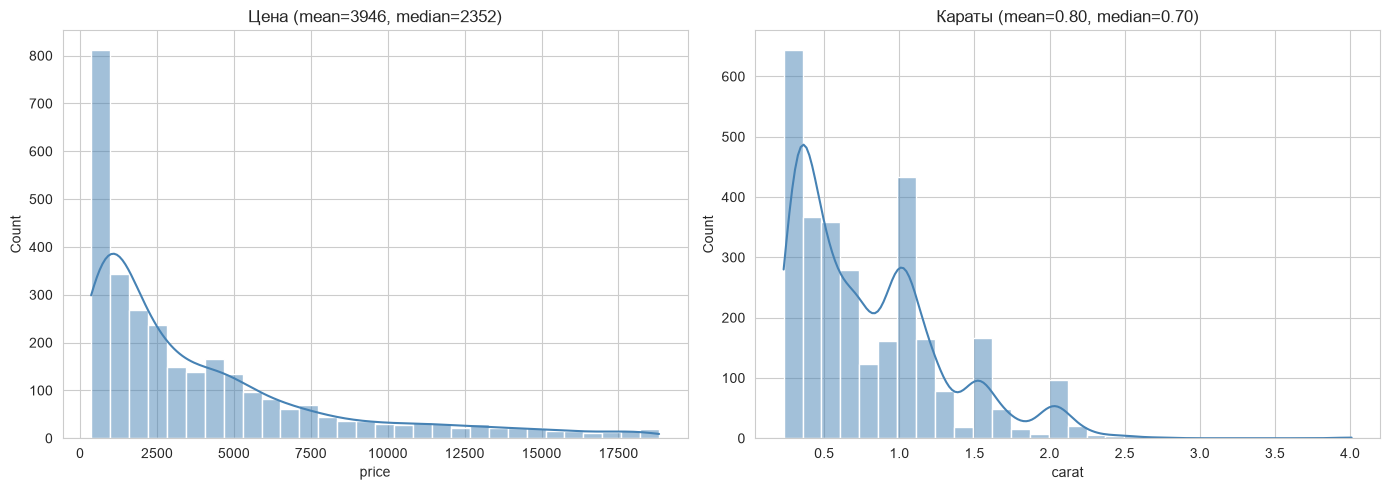

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(diamonds['price'], bins=30, kde=True, ax=axes[0], color='steelblue')
mean_price = diamonds['price'].mean()
med_price = diamonds['price'].median()
axes[0].set_title(f'Цена (mean={mean_price:.0f}, median={med_price:.0f})')

sns.histplot(diamonds['carat'], bins=30, kde=True, ax=axes[1], color='steelblue')
mean_carat = diamonds['carat'].mean()
med_carat = diamonds['carat'].median()
axes[1].set_title(f'Караты (mean={mean_carat:.2f}, median={med_carat:.2f})')

plt.tight_layout()
plt.show()

# -> plot_histograms(diamonds, ['price', 'carat'])

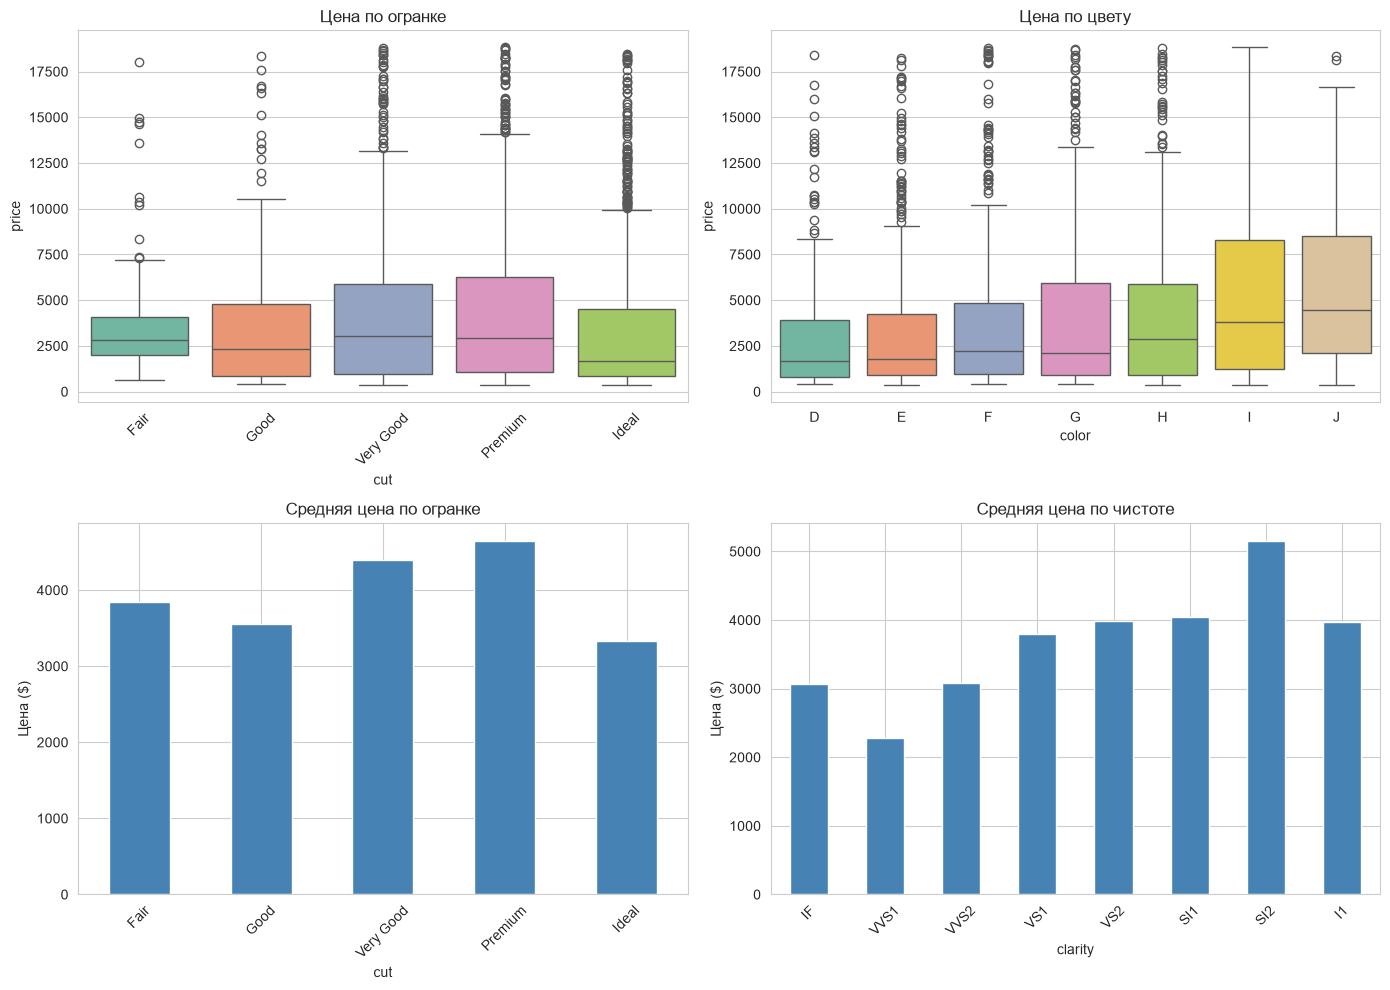

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

cut_order = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']

sns.boxplot(data=diamonds, x='cut', y='price', order=cut_order,
            palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('Цена по огранке')
axes[0, 0].tick_params(axis='x', rotation=45)

sns.boxplot(data=diamonds, x='color', y='price', palette='Set2', ax=axes[0, 1])
axes[0, 1].set_title('Цена по цвету')

diamonds.groupby('cut')['price'].mean().reindex(cut_order).plot.bar(
    ax=axes[1, 0], color='steelblue', edgecolor='white')
axes[1, 0].set_title('Средняя цена по огранке')
axes[1, 0].set_ylabel('Цена ($)')
axes[1, 0].tick_params(axis='x', rotation=45)

diamonds.groupby('clarity')['price'].mean().plot.bar(
    ax=axes[1, 1], color='steelblue', edgecolor='white')
axes[1, 1].set_title('Средняя цена по чистоте')
axes[1, 1].set_ylabel('Цена ($)')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# -> plot_boxplots(diamonds, [('cut','price'), ('color','price')])
# -> plot_bars(diamonds, 'cut', 'price')
# -> plot_bars(diamonds, 'clarity', 'price')

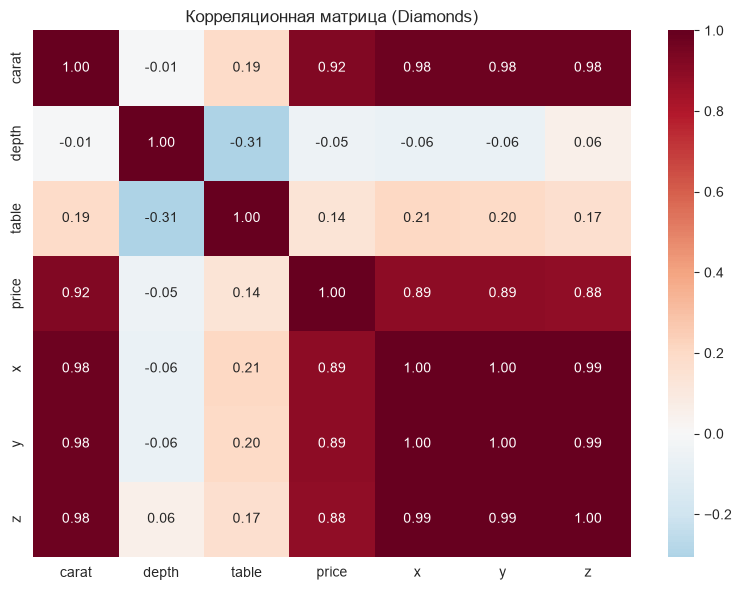

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
cols = ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']
sns.heatmap(diamonds[cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Корреляционная матрица (Diamonds)')
plt.tight_layout()
plt.show()

# -> plot_heatmap(diamonds, cols=['carat','depth','table','price','x','y','z'])

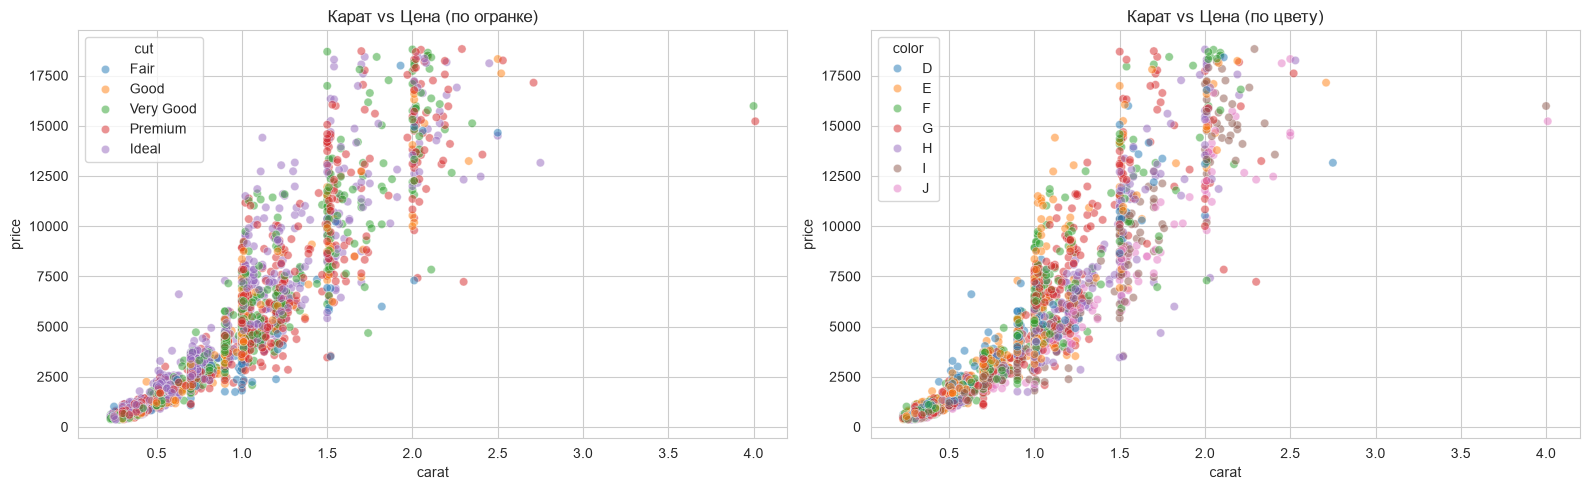

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.scatterplot(data=diamonds, x='carat', y='price', hue='cut',
                hue_order=['Fair', 'Good', 'Very Good', 'Premium', 'Ideal'],
                alpha=0.5, ax=axes[0])
axes[0].set_title('Карат vs Цена (по огранке)')

sns.scatterplot(data=diamonds, x='carat', y='price', hue='color',
                alpha=0.5, ax=axes[1])
axes[1].set_title('Карат vs Цена (по цвету)')

plt.tight_layout()
plt.show()

# -> plot_scatter(diamonds, 'carat', 'price', 'cut')
# -> plot_scatter(diamonds, 'carat', 'price', 'color')

**Выводы (Diamonds):**
- `carat` - главный предиктор цены (Спирмен > Пирсон, связь монотонная но не строго линейная)
- Ideal огранка может быть дешевле - Ideal чаще на мелких камнях (confounding variable)
- Цена: mean >> median - длинный правый хвост, много дешёвых камней и мало дорогих